# Unidad 36 — Pandas DataFrame para procesamiento de datos

Semana 5 · Clase 2 · Fuente: PDF parte 2, págs. 144–251

[Índice de la semana](../semana-05.ipynb) | [Anterior](u35-series-de-pandas.ipynb) | [Siguiente](../repaso.ipynb)

In [1]:
def verificar(descripcion, obtenido, esperado):
    """Compara el resultado de un ejercicio con el esperado e informa sin detener el notebook."""
    if obtenido == esperado:
        print(f"Correcto: {descripcion}")
    else:
        print(f"Incorrecto: {descripcion}. Se esperaba {esperado!r} y se obtuvo {obtenido!r}")

## Objetivos de la unidad

Según el PDF (págs. 145–147):

- Explicar la estructura de un DataFrame a partir de una estructura de datos bidimensional.
- Convertir un objeto diccionario en un DataFrame.
- Renombrar filas, columnas e índices de un DataFrame.
- Crear un DataFrame importando archivos externos en formato CSV, Excel y JSON.
- Crear DataFrames importando conjuntos de datos existentes a través de una API.
- Editar la información de filas y columnas de un DataFrame ya creado.

Conceptos previos que el PDF da por sabidos: los objetos Series de pandas, los dos tipos de estructuras de datos de pandas y el uso de Matplotlib.

Palabras clave: **DataFrame**, **E/S de pandas**, **filas en DataFrame**, **columnas en DataFrame**, **elementos de datos en DataFrame**, **API de lectura de datos**.

**Ampliación (no está en el PDF):** el contexto del docente añade como objetivos de la unidad la aritmética y las estadísticas descriptivas básicas, y los gráficos de líneas, de barras y de dispersión. El PDF solo trata `describe()`, `corr()` y el gráfico de dispersión, por lo que el resto se desarrolla en la sección de ampliación y se marca como tal.

**Referencia:** PDF parte 2, págs. 145–147

## Contexto

Casi todo el análisis de datos parte de datos tabulares: hojas de cálculo, archivos CSV o respuestas de servicios web. Un **DataFrame** es la estructura de pandas pensada para ese formato: una tabla bidimensional con filas y columnas etiquetadas, donde **cada columna es una Serie**. A diferencia de una Serie, que solo guarda un valor por etiqueta de índice, un DataFrame guarda varios valores por etiqueta.

La misión de la unidad es "importar datos externos para encontrar y ordenar los elementos de datos que se desean". El PDF propone descargar de Kaggle el conjunto de las canciones más reproducidas de 2019 en Spotify, averiguar qué artista tiene más canciones populares, comprobar mediante un gráfico de dispersión si el tempo de la música se relaciona con la popularidad y, por último, guardar una lista de reproducción de un artista en un archivo Excel para compartirla.

El vocabulario del docente que se usa en toda la unidad:

- **DataFrame**: tabla de filas y columnas; cada columna es una Serie.
- **Índice**: etiquetas de las filas (también pueden ser jerárquicas).
- **API**: servicio remoto que entrega datos; `pandas-datareader` los convierte directamente en un DataFrame.

**Ampliación (no está en el PDF):** los archivos de datos que el PDF carga desde Kaggle no se pueden descargar sin una cuenta, y el notebook debe funcionar sin conexión. Por eso se incluyen copias o reproducciones en `../datos/` con el prefijo `u36-`. Cada una se describe donde se usa; en particular, el conjunto de Spotify del PDF se reemplaza por otro público con la misma idea (ver "Nota sobre los datos" más adelante).

**Referencia:** PDF parte 2, págs. 148–149

In [2]:
import json
import tempfile
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Carpeta con los archivos de datos de la unidad (relativa a este notebook)
DATOS = Path("..") / "datos"
# Carpeta temporal: aquí se escriben todos los archivos que generan los ejemplos
TMP = Path(tempfile.mkdtemp(prefix="u36-"))

print("pandas", pd.__version__)
print("Archivos de datos:", sorted(p.name for p in DATOS.glob("u36-*")))

pandas 3.1.0
Archivos de datos: ['u36-esperanza-vida-bm.csv', 'u36-fred-gs10.csv', 'u36-players.xlsx', 'u36-spotify-top-hits.csv', 'u36-titanic-test.csv', 'u36-titanic-train.csv', 'u36-universities-ranking.json']


## 1. Qué es un DataFrame

Un DataFrame es una estructura de datos bidimensional con etiquetas, formada por filas y columnas. Los datos tabulares y las hojas de Excel que aparecen en el análisis de datos tienen este formato. Cada columna es una Serie y todas comparten el mismo índice de filas.

El PDF resume el vocabulario de estadística y ciencia de datos así:

| Término | Significado | Términos similares |
|---|---|---|
| DataFrame | La estructura tipo hoja de cálculo más básica en estadística y aprendizaje automático. | Tabla |
| Característica | Normalmente cada columna de la tabla. | Atributo, predictor, variable |
| Resultado | Lo que la mayoría de los proyectos de ciencia de datos intenta predecir; la característica se usa para predecirlo. | Variable dependiente, respuesta, objetivo |
| Registro | Normalmente cada fila de la tabla. | Caso, ejemplo, observación, patrón, muestra |

En otras palabras: un DataFrame es una matriz bidimensional en la que cada **fila** es un registro (caso) y cada **columna** es una característica (variable). En pandas se pueden definir índices múltiples o jerárquicos, lo que permite un procesamiento más complejo.

**Clave:** Series = una dimensión; DataFrame = dos dimensiones, con una Serie por columna.

**Referencia:** PDF parte 2, págs. 151–152

## 2. Creación de un DataFrame a partir de un diccionario

Varias matrices unidimensionales de la misma longitud (o varias Series) se combinan en un DataFrame. Como el objeto que agrupa varias Series es un diccionario, también se entiende como "convertir un diccionario en un DataFrame": cada **clave** pasa a ser una **columna** y los datos de la lista pasan a ser los **elementos**. La sintaxis es `pd.DataFrame(objeto_diccionario)`.

El ejemplo del PDF combina dos Series con índices distintos; pandas alinea por etiqueta y rellena con `NaN` lo que falta (la etiqueta `"d"` no existe en `s`):

In [3]:
s = pd.Series([1.0, 2.0, 3.0], index=["a", "b", "c"])
s2 = pd.Series([1.0, 2.0, 3.0, 4.0], index=["a", "b", "c", "d"])

data = {"one": s, "two": s2}

print(pd.DataFrame(data))

   one  two
a  1.0  1.0
b  2.0  2.0
c  3.0  3.0
d  NaN  4.0


También se puede partir de listas de la misma longitud. Si las longitudes no coinciden, pandas lanza un `ValueError`:

In [4]:
tabla = pd.DataFrame({"nombre": ["Ana", "Luis", "Carla"], "edad": [23, 30, 27]})
print(tabla)
print()

try:
    pd.DataFrame({"nombre": ["Ana", "Luis"], "edad": [23, 30, 27]})
except ValueError as error:
    print("ValueError:", error)

  nombre  edad
0    Ana    23
1   Luis    30
2  Carla    27

ValueError: All arrays must be of the same length


**Error común:** mezclar listas de distinta longitud en el diccionario. Todas las columnas deben tener el mismo número de elementos (o ser Series, que se alinean por índice).

**Referencia:** PDF parte 2, págs. 153–154

### 2.1 Nombres de filas (índice) y de columnas

Los nombres de fila y de columna se pueden fijar al crear el DataFrame o después. Cada columna es un objeto Series y las Series se combinan por el índice de la misma fila. Hay dos formas:

- **Cambiar todos los nombres:** asignar un arreglo nuevo a `df.index` (filas) o a `df.columns` (columnas).
- **Cambiar solo algunos:** `df.rename(index={antiguo: nuevo})` y `df.rename(columns={antiguo: nuevo})`. Con `inplace=True` el cambio se hace sobre el propio objeto.

In [5]:
d = {"col1": [1, 2], "col2": [3, 4]}
df = pd.DataFrame(data=d)
print(df)

df.index = ["new index0", "new index1"]
print(df)

df.columns = ["new_col1", "new_col2"]
print(df)

   col1  col2
0     1     3
1     2     4
            col1  col2
new index0     1     3
new index1     2     4
            new_col1  new_col2
new index0         1         3
new index1         2         4


Ejemplo de `rename()` con el código de la diapositiva:

In [6]:
d = {"col1": [1, 2], "col2": [3, 4]}
df = pd.DataFrame(d)
df.rename(index={0: "new index0"}, inplace=True)   # cambia df
df.rename(columns={"col2": "new col2"})            # devuelve una copia; df no cambia

/var/folders/xp/xx59bb5s1n31zc4kh2lnljyc0000gn/T/ipykernel_25897/1412948647.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(index={0: "new index0"}, inplace=True)   # cambia df


,col1,new col2
new index0,1,3
1,2,4


**Nota sobre el PDF:** en la diapositiva, la línea 4 usa `inplace=True`, pero la línea 5 (`rename(columns=...)`) no lo usa. La tabla que muestra la diapositiva es el valor **devuelto** por la línea 5, no el contenido de `df`. El texto afirma que "el propio objeto original se ha cambiado" con respecto a las columnas, y eso no es cierto: sin `inplace=True` el resultado hay que guardarlo. Comprobación:

In [7]:
print("Columnas de df tras la línea 5:", list(df.columns))

df = df.rename(columns={"col2": "new col2"})   # forma recomendada: reasignar
print("Columnas de df tras reasignar: ", list(df.columns))

Columnas de df tras la línea 5: ['col1', 'col2']
Columnas de df tras reasignar:  ['col1', 'new col2']


**Nota sobre el PDF (pandas 3.1):** el parámetro `inplace` está **en desuso**: la celda anterior emite un `Pandas4Warning` ("The inplace keyword in DataFrame.rename is deprecated"). Hoy se prefiere reasignar (`df = df.rename(...)`). El propio PDF lo reconoce más adelante (pág. 213): conviene copiar el original con `copy()` y trabajar sobre la copia.

**Clave:** `df.index = [...]` y `df.columns = [...]` cambian todos los nombres; `rename()` cambia solo los indicados.

**Referencia:** PDF parte 2, págs. 155–157

### 2.2 Alternativa: `DataFrame.from_dict()` (Un paso más)

`pd.DataFrame.from_dict(diccionario, orient="columns")` convierte un diccionario de objetos tipo arreglo. Con `orient="columns"` (valor por defecto) las claves son las columnas; con `orient="index"` las claves son las filas, y entonces se pueden dar los nombres de columna con `columns=`.

In [8]:
s = pd.Series([1.0, 2.0, 3.0], index=["a", "b", "c"])
s2 = pd.Series([1.0, 2.0, 3.0, 4.0], index=["a", "b", "c", "d"])
dic_data = {"one": s, "two": s2}

print(type(dic_data))
print(pd.DataFrame.from_dict(dic_data))
print()
print(pd.DataFrame.from_dict(dic_data, orient="index"))
print()

data = {"row_1": [3, 2, 1, 0], "row_2": ["a", "b", "c", "d"]}
print(pd.DataFrame.from_dict(data, orient="index", columns=["A", "B", "C", "D"]))

<class 'dict'>
   one  two
a  1.0  1.0
b  2.0  2.0
c  3.0  3.0
d  NaN  4.0

       a    b    c    d
one  1.0  2.0  3.0  NaN
two  1.0  2.0  3.0  4.0

       A  B  C  D
row_1  3  2  1  0
row_2  a  b  c  d


**Nota sobre el PDF:** el texto de la diapositiva escribe `.from_dic()` y `orient = 'columnas'`; el método real es `from_dict()` y el valor es `'columns'` (traducción automática).

**Referencia:** PDF parte 2, págs. 158–159

## 3. Conversión de otros objetos de datos: la API de E/S de pandas

La conversión de otros tipos de datos (diccionarios, archivos) en un DataFrame se llama a veces la **entrada** al DataFrame. pandas lo hace con herramientas de E/S (entrada/salida): texto, CSV, Excel, JSON, HDF5, etc. La lista completa está en la guía oficial: https://pandas.pydata.org/docs/user_guide/io.html. Cada formato tiene una función de lectura `pd.read_...()` y una de escritura `df.to_...()`.

| Formato | Leer | Escribir |
|---|---|---|
| CSV | `pd.read_csv()` | `df.to_csv()` |
| Excel | `pd.read_excel()` | `df.to_excel()` |
| JSON | `pd.read_json()` | `df.to_json()` |

**Referencia:** PDF parte 2, pág. 160

### 3.1 Rutas de archivos

Uno de los errores más comunes de quien empieza es escribir una ruta incorrecta al cargar un archivo. Las rutas pueden ser de dos tipos:

- **Ruta absoluta:** recorre todo el camino desde el punto de partida del sistema operativo hasta el archivo (por ejemplo, `C:\Users\UserID\Desktop\sample.txt` en Windows). Es una cadena estática que solo vale en ese equipo.
- **Ruta relativa:** indica la ubicación del archivo **a partir de la ubicación actual**.

| Símbolo | Significado |
|---|---|
| `/` | Directorio de nivel superior (raíz) |
| `./` | El mismo directorio actual (se puede omitir) |
| `../` | Directorio padre del actual |
| `../../` | Dos niveles por encima |

Ejemplos del PDF (rutas de una página web, con la misma lógica): `imagen.jpg` está en la misma carpeta; `images/picture.jpg` está en la subcarpeta `images`; `/images/picture.jpg` está en la carpeta `images` de la raíz; `../imagen.jpg` está un nivel por encima de la carpeta actual.

**Por qué se necesitan rutas relativas:** si la ubicación cambia con frecuencia, o si el proyecto se usa en distintos sistemas operativos, habría que reescribir o mantener una ruta absoluta para cada caso. Una ruta relativa funciona en cualquier equipo mientras la estructura de carpetas se mantenga.

In [9]:
print("Carpeta de trabajo actual:", Path.cwd().name)
print("Ruta relativa a los datos:", DATOS)
print("Existe el archivo:", (DATOS / "u36-titanic-test.csv").exists())

Carpeta de trabajo actual: clase-2-modulos-y-pandas
Ruta relativa a los datos: ../datos
Existe el archivo: True


**Error común:** la ruta relativa depende de dónde se ejecuta el notebook. Este notebook está en `clase-2-modulos-y-pandas/`, por eso los datos están en `../datos/`.

**Referencia:** PDF parte 2, págs. 161–163

### 3.2 Revisar los datos: `head()`, `shape`, `len()` y `columns`

`DataFrame.head(n)` devuelve las primeras `n` filas (5 por defecto). Sirve para comprobar el resultado mientras se procesan los datos. Con un número negativo, `head(-n)` devuelve **todas las filas excepto las últimas `n`**.

Otras funciones para revisar: `df.shape` devuelve una tupla (filas, columnas); `len(df)` da el número de filas; `df.columns` muestra los nombres de columna.

In [10]:
df = pd.DataFrame({"animal": ["alligator", "bee", "falcon", "lion", "monkey", "parrot", "shark", "whale", "zebra"]})

print(df.head())
print()
print(df.head(3))
print()
print(df.head(-3))
print()
print("shape:", df.shape)
print("len:", len(df))
print("columns:", df.columns)

      animal
0  alligator
1        bee
2     falcon
3       lion
4     monkey

      animal
0  alligator
1        bee
2     falcon

      animal
0  alligator
1        bee
2     falcon
3       lion
4     monkey
5     parrot

shape: (9, 1)
len: 9
columns: Index(['animal'], dtype='str')


**Nota sobre el PDF:** la salida que muestra la diapositiva para `df.head(-3)` tiene solo 3 filas (alligator, bee, falcon), igual que `head(3)`. Con 9 filas, `head(-3)` devuelve las 6 primeras, como se ve arriba. La salida de la diapositiva no corresponde al código.

**Clave:** `shape` devuelve `(filas, columnas)`; `len(df)` devuelve el número de filas.

**Referencia:** PDF parte 2, págs. 164–169

## 4. Convertir un archivo CSV en un DataFrame

En un archivo **CSV** (*comma-separated values*) las columnas se separan con comas y las filas con saltos de línea. Se lee con `pd.read_csv("ruta")`.

El PDF usa el archivo de supervivientes del Titanic de Kaggle (`test.csv`, con 418 pasajeros y 11 columnas).

**Ampliación (no está en el PDF):** el PDF pide descargar el archivo de Kaggle; aquí se incluyen copias en `../datos/` (`u36-titanic-test.csv` y `u36-titanic-train.csv`), tomadas de un repositorio público de GitHub que replica los archivos de la competición (`agconti/kaggle-titanic`, carpeta `data`).

In [11]:
titanic = pd.read_csv(DATOS / "u36-titanic-test.csv")
titanic.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


### 4.1 `info()` y `describe()`

`info()` informa del número total de filas, del tipo de dato de cada columna y de cuántos valores no nulos tiene cada una. El PDF recomienda usarlo siempre primero, como hábito, al preprocesar datos. `describe()` resume la distribución de las columnas numéricas, algo muy importante antes de aplicar aprendizaje automático.

In [12]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 36.1 KB


**Nota sobre el PDF:** la diapositiva señala "417 filas" en el rango del índice. En realidad `RangeIndex: 418 entries, 0 to 417`: hay 418 filas, con índices de 0 a 417. Además, la tabla de `describe()` de la diapositiva siguiente (891 pasajeros, con columna `Survived`) corresponde al archivo `train.csv`, no a `test.csv`. Aquí se reproduce con `train.csv`:

In [13]:
titanic_train = pd.read_csv(DATOS / "u36-titanic-train.csv")
titanic_train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Significado de las filas de `describe()` según el PDF:

| Fila | Significado |
|---|---|
| `count` | Número de valores no nulos (ampliación: el PDF no la lista) |
| `mean` | Valor medio de todos los datos |
| `std` | Desviación típica |
| `min` | Valor mínimo |
| `25%` | Valor del percentil 25 |
| `50%` | Valor del percentil 50 (mediana) |
| `75%` | Valor del percentil 75 |
| `max` | Valor máximo |

**Nota sobre el PDF:** en la columna `Age` de `train.csv` hay 714 valores no nulos de 891: `count` no es igual en todas las columnas cuando faltan datos.

**Referencia:** PDF parte 2, págs. 170–174

### 4.2 Parámetros de `read_csv()`

Antes de cargar un archivo hay que **abrirlo y comprobar su estructura**: cómo está organizado y qué parámetros conviene fijar.

**a) `sep` y `nrows`.** La mayoría de los CSV usan coma, pero algunos usan tabulaciones (`sep="\t"`) o barras verticales (`sep="|"`). `nrows` indica cuántas filas leer.

In [14]:
texto_tsv = "a\tb\tc\n1\t2\t3\n4\t5\t6\n7\t8\t9\n"

print(pd.read_csv(StringIO(texto_tsv)))            # sin sep: una sola columna
print()
print(pd.read_csv(StringIO(texto_tsv), sep="\t"))   # con sep: tres columnas
print()
print(pd.read_csv(StringIO(texto_tsv), sep="\t", nrows=2))
print()
print(pd.read_csv(DATOS / "u36-titanic-test.csv", nrows=3))

   a\tb\tc
0  1\t2\t3
1  4\t5\t6
2  7\t8\t9

   a  b  c
0  1  2  3
1  4  5  6
2  7  8  9

   a  b  c
0  1  2  3
1  4  5  6

   PassengerId  Pclass                              Name     Sex   Age  SibSp  \
0          892       3                  Kelly, Mr. James    male  34.5      0   
1          893       3  Wilkes, Mrs. James (Ellen Needs)  female  47.0      1   
2          894       2         Myles, Mr. Thomas Francis    male  62.0      0   

   Parch  Ticket    Fare  Cabin Embarked  
0      0  330911  7.8292    NaN        Q  
1      0  363272  7.0000    NaN        S  
2      0  240276  9.6875    NaN        Q  


**b) `skiprows`.** Salta `n` líneas del inicio al importar; también puede ser una lista con los números de línea que se omiten. Con `skiprows=2` se omiten la línea del encabezado y la primera fila de datos, así que la segunda fila de datos (Wilkes) se convierte en encabezado, como muestra la diapositiva (incluido el nombre `Unnamed: 9` de la columna que quedó vacía).

In [15]:
titanic = pd.read_csv(DATOS / "u36-titanic-test.csv", skiprows=2)

titanic.head(5)

,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47,1,0,363272,7,Unnamed: 9,S
0,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
1,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
2,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
3,897,3,"Svensson, Mr. Johan Cervin",male,14.0,0,0,7538,9.2250,NaN,S
4,898,3,"Connolly, Miss. Kate",female,30.0,0,0,330972,7.6292,NaN,Q


**c) `header`.** Indica qué fila se usa como nombres de columna. Por defecto es `header=0`: la primera fila del archivo. Con `header=2`, la fila de índice 2 pasa a ser el encabezado y las anteriores se descartan. Con `header=None` el archivo no tiene encabezado, y entonces los nombres se dan con `names=[...]`.

In [16]:
ruta = DATOS / "u36-titanic-test.csv"

print(pd.read_csv(ruta, header=0).head(2))          # por defecto
print()
print(pd.read_csv(ruta, header=2).head(2))          # la fila de índice 2 es el encabezado
print()
print(pd.read_csv(ruta, header=None).head(2))       # sin encabezado: columnas 0, 1, 2...
print()
nombres = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k"]
print(pd.read_csv(ruta, header=None, names=nombres).head(2))

   PassengerId  Pclass                              Name     Sex   Age  SibSp  \
0          892       3                  Kelly, Mr. James    male  34.5      0   
1          893       3  Wilkes, Mrs. James (Ellen Needs)  female  47.0      1   

   Parch  Ticket    Fare Cabin Embarked  
0      0  330911  7.8292   NaN        Q  
1      0  363272  7.0000   NaN        S  

   893  3 Wilkes, Mrs. James (Ellen Needs) female    47  1  0  363272       7  \
0  894  2        Myles, Mr. Thomas Francis   male  62.0  0  0  240276  9.6875   
1  895  3                 Wirz, Mr. Albert   male  27.0  0  0  315154  8.6625   

  Unnamed: 9  S  
0        NaN  Q  
1        NaN  S  

            0       1                 2     3     4      5      6       7   \
0  PassengerId  Pclass              Name   Sex   Age  SibSp  Parch  Ticket   
1          892       3  Kelly, Mr. James  male  34.5      0      0  330911   

       8      9         10  
0    Fare  Cabin  Embarked  
1  7.8292    NaN         Q  

       

Cuándo usar `header=None`: después de comprobar el CSV, cuando los datos empiezan en la primera fila y no hay una fila con los nombres. Con `names=[...]` se asignan los encabezados. Si se dan **más** nombres que columnas tiene el archivo, la columna sobrante se llena con `NaN` (ejemplo con 12 nombres):

In [17]:
nombres12 = list("abcdefghijkl")
print(pd.read_csv(ruta, header=None, names=nombres12).head(2))

             a       b                 c     d     e      f      g       h  \
0  PassengerId  Pclass              Name   Sex   Age  SibSp  Parch  Ticket   
1          892       3  Kelly, Mr. James  male  34.5      0      0  330911   

        i      j         k   l  
0    Fare  Cabin  Embarked NaN  
1  7.8292    NaN         Q NaN  


**Nota sobre el PDF:** en la diapositiva, el título de esta variante aparece como `headheader= Ninguno` y los parámetros como `cabecera`, `nombre_hoja` o `encabezado`: son traducciones automáticas. Los nombres reales de los parámetros son `header`, `sheet_name` y `names`, y el valor es `None`. Observa además que con `header=None` la fila que antes era el encabezado (`PassengerId`, `Pclass`...) pasa a ser una fila de datos, y todas las columnas se vuelven de tipo texto.

**d) `encoding`.** Sirve para leer y para escribir. La codificación transforma el texto a bytes; ASCII solo cubre los caracteres de 0 a 127, así que otros alfabetos y los acentos necesitan otras codificaciones. Si el texto aparece "roto" con `encoding="utf-8"`, el PDF sugiere guardar el archivo como UTF-8 desde Excel. La lista de codificaciones está en https://docs.python.org/3/library/codecs.html#standard-encodings.

**Ampliación (no está en el PDF):** ejemplo con un archivo guardado en `latin-1` y leído con distintas codificaciones.

In [18]:
ruta_latin = TMP / "nombres-latin1.csv"
pd.DataFrame({"ciudad": ["Panamá", "Bogotá"], "habitantes": [880691, 7181469]}).to_csv(
    ruta_latin, index=False, encoding="latin-1"
)

print(pd.read_csv(ruta_latin, encoding="latin-1"))      # codificación correcta
print()
try:
    pd.read_csv(ruta_latin, encoding="utf-8")           # codificación incorrecta
except UnicodeDecodeError as error:
    print("UnicodeDecodeError:", error.reason)

   ciudad  habitantes
0  Panamá      880691
1  Bogotá     7181469

UnicodeDecodeError: unexpected end of data


**e) `index_col`.** Especifica qué columna se usa como índice de filas, en lugar del índice numérico por defecto.

In [19]:
titanic = pd.read_csv(DATOS / "u36-titanic-test.csv", index_col="Name")
titanic.head(2)

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Name,,,,,,,,,,
"Kelly, Mr. James",892,3,male,34.5,0,0,330911,7.8292,NaN,Q
"Wilkes, Mrs. James (Ellen Needs)",893,3,female,47.0,1,0,363272,7.0000,NaN,S


**Clave:** antes de leer un CSV, abrirlo y comprobar el delimitador, la fila de encabezado y la codificación; después, `head()`, `info()` y `describe()`.

**Error común:** olvidar `sep` en un archivo separado por tabulaciones o punto y coma: todo queda en una sola columna.

**Referencia:** PDF parte 2, págs. 175–182

## 5. Convertir un archivo Excel en un DataFrame

Las filas y columnas de Excel se corresponden una a una con las del DataFrame. Se lee con `pd.read_excel(ruta, sheet_name=0, header=0)`. El parámetro `sheet_name` elige la hoja: puede ser el nombre real de la hoja o un entero que empieza en 0; también acepta una lista, por ejemplo `[0, 1, 2, "nombres"]` carga la primera, la segunda, la tercera y la hoja llamada "nombres" (el resultado es un diccionario de DataFrames). El parámetro `header` indica la fila que se usa como columnas.

El PDF usa los datos de jugadores de la NBA de Kaggle (`Players.xls`).

**Ampliación (no está en el PDF):** el archivo original no está disponible sin cuenta de Kaggle. En `../datos/u36-players.xlsx` hay una reproducción de las **5 filas que muestra la diapositiva 184** (transcritas de la imagen), con las mismas columnas, incluida `Unnamed: 0`, que es el índice que quedó guardado como columna, y el nombre `collage` tal como figura en el original. No son los datos completos de Kaggle.

In [20]:
df = pd.read_excel(DATOS / "u36-players.xlsx", sheet_name=0, header=0)

df.head(5)

,Unnamed: 0,Player,height,weight,collage,born,birth_city,birth_state
0,0,Curly Armstrong,180,77,Indiana University,1918,NaN,NaN
1,1,Cliff Barker,188,83,University of Kentucky,1921,Yorktown,Indiana
2,2,Leo Barnhorst,193,86,University of Notre Dame,1924,NaN,NaN
3,3,Ed Bartels,196,88,North Carolina State University,1925,NaN,NaN
4,4,Ralph Beard,178,79,University of Kentucky,1927,Hardinsburg,Kentucky


Con una lista en `sheet_name` se obtiene un diccionario con un DataFrame por hoja (ampliación):

In [21]:
varias = pd.read_excel(DATOS / "u36-players.xlsx", sheet_name=[0, "Players"])
print(type(varias), list(varias.keys()))

<class 'dict'> [0, 'Players']


**Nota sobre el PDF:** la advertencia de la diapositiva dice que hay que instalar `xlrd` (`cond install xlrd`, que es `conda install`). En las versiones actuales de pandas, `xlrd` solo lee archivos `.xls` antiguos; para `.xlsx` se necesita **`openpyxl`**, que es el motor que se usa aquí (se instaló con `uv add openpyxl`). Escribir Excel con `to_excel()` también requiere `openpyxl`.

**Error común:** `ImportError: Missing optional dependency 'openpyxl'`: falta instalar el motor del formato que se está leyendo.

**Referencia:** PDF parte 2, págs. 183–185

## 6. Convertir un archivo JSON en un DataFrame

**JSON** (*JavaScript Object Notation*) es un formato creado para compartir datos, formado por pares atributo-valor (clave-valor) y matrices. Los valores pueden ser cadenas, números, matrices, booleanos, `null` y otros objetos. Si se guarda como archivo, la extensión es `.json`; el tipo de contenido de una solicitud HTTP es `application/json`.

- **Objeto JSON:** pares nombre-valor entre llaves `{}`, separados por comas.
- **Matriz (array) JSON:** varios objetos separados por comas entre corchetes `[]`.

In [22]:
objeto_json = """{
  "name": "cherry",
  "family": "Shih Tzu",
  "age": 14,
  "weight": 4.5
}"""
print(json.loads(objeto_json))    # un objeto se convierte en un diccionario de Python
print()

matriz_json = """[
  {"name": "cherry", "family": "Shih Tzu", "age": 14, "weight": 4.5},
  {"name": "cola", "family": "Terrier", "age": 1, "weight": 2.5},
  {"name": "baby", "family": "Maltese", "age": 14, "weight": 4.5}
]"""
print(json.loads(matriz_json))    # una matriz se convierte en una lista de diccionarios

{'name': 'cherry', 'family': 'Shih Tzu', 'age': 14, 'weight': 4.5}

[{'name': 'cherry', 'family': 'Shih Tzu', 'age': 14, 'weight': 4.5}, {'name': 'cola', 'family': 'Terrier', 'age': 1, 'weight': 2.5}, {'name': 'baby', 'family': 'Maltese', 'age': 14, 'weight': 4.5}]


**Referencia:** PDF parte 2, págs. 186–189

### 6.1 `pd.read_json(ruta, orient=None)`

El PDF carga un archivo JSON con el ranking mundial de universidades 2021 (Kaggle, `universities_ranking.json`) con `orient="records"`. La ruta también puede ser una URL.

**Ampliación (no está en el PDF):** el archivo original tiene 1526 filas y no está disponible sin cuenta de Kaggle. En `../datos/u36-universities-ranking.json` hay una reproducción de las **20 primeras filas (ranking 1 a 20)** transcritas de la diapositiva 211, con las mismas siete columnas y los mismos formatos (por ejemplo, `"20,774"` y `"41%"` como texto). No son los datos completos.

In [23]:
df = pd.read_json(DATOS / "u36-universities-ranking.json", orient="records")

df.head()

,ranking,title,location,number students,students staff ratio,perc intl students,gender ratio
0,1,University of Oxford,United Kingdom,"20,774",11.1,41%,46 : 54
1,2,Stanford University,United States,"16,223",7.4,23%,44 : 56
2,3,Harvard University,United States,"21,261",9.3,25%,49 : 51
3,4,California Institute of Technology,United States,"2,238",6.3,33%,36 : 64
4,5,Massachusetts Institute of Technology,United States,"11,276",8.4,34%,39 : 61


**Parámetro `orient`.** Indica cómo está estructurado el JSON. Se debe abrir el JSON antes de cargarlo y elegir la opción que coincide; en lugar de memorizarlas, conviene probarlas una a una. El valor por defecto es `None`.

| `orient` | Estructura |
|---|---|
| `'columns'` | `{columna: {índice: valor, ...}, ...}` |
| `'split'` | `{"index": [...], "columns": [...], "data": [...]}` |
| `'records'` | `[{columna: valor}, ..., {columna: valor}]` |
| `'index'` | `{índice: {columna: valor, ...}, ...}` |
| `'values'` | Solo la matriz de valores |

**Ampliación (no está en el PDF):** el mismo DataFrame escrito con `to_json()` en cada orientación, y leído de nuevo.

In [24]:
base = pd.DataFrame({"name": ["cherry", "cola"], "age": [14, 1]})

for orient in ["columns", "split", "records", "index", "values"]:
    texto = base.to_json(orient=orient)
    print(f"{orient:8s}", texto)

print()
print(pd.read_json(StringIO(base.to_json(orient="records")), orient="records"))

columns  {"name":{"0":"cherry","1":"cola"},"age":{"0":14,"1":1}}
split    {"columns":["name","age"],"index":[0,1],"data":[["cherry",14],["cola",1]]}
records  [{"name":"cherry","age":14},{"name":"cola","age":1}]
index    {"0":{"name":"cherry","age":14},"1":{"name":"cola","age":1}}
values   [["cherry",14],["cola",1]]

     name  age
0  cherry   14
1    cola    1


**Nota sobre el PDF (pandas 3):** `read_json()` ya no acepta un texto JSON literal: lo interpreta como una ruta y falla con `FileNotFoundError`. Hay que envolver el texto en `StringIO` como arriba (o guardarlo en un archivo). Una ruta de archivo o una URL siguen funcionando igual.

**Advertencia del PDF:** lo que se aprende aquí es cargar un JSON en un DataFrame con pandas. Es distinto de usar el módulo `json` de Python para convertir un texto JSON en un objeto de Python (`json.loads`), que es lo que se hizo en la celda anterior.

Escritura (ampliación): `df.to_json(ruta)` guarda un JSON.

In [25]:
ruta_json = TMP / "universidades.json"
df.head(3).to_json(ruta_json, orient="records", force_ascii=False)

print(ruta_json.read_text(encoding="utf-8")[:200], "...")
print(pd.read_json(ruta_json).shape)

[{"ranking":1,"title":"University of Oxford","location":"United Kingdom","number students":"20,774","students staff ratio":11.1,"perc intl students":"41%","gender ratio":"46 : 54"},{"ranking":2,"title ...
(3, 7)


**Clave:** `orient` debe coincidir con la estructura real del JSON; ante la duda, abrir el archivo.

**Referencia:** PDF parte 2, págs. 190–191

## 7. Leer datos de un servicio remoto con la API DataReader

El paquete `pandas-datareader` (`pip install pandas-datareader`) permite acceder a distintas fuentes de datos remotas y procesarlas directamente como DataFrame. El ejemplo del PDF obtiene con dos líneas el rendimiento a 10 años de vencimiento constante de la deuda pública de Estados Unidos (símbolo `GS10` en la base de datos FRED de la Reserva Federal de San Luis):

```python
import matplotlib.pyplot as plt
import pandas_datareader as pdr

df = pdr.get_data_fred('GS10')

plt.plot(df)
plt.show()
```

Fuentes disponibles según el PDF: Tiingo, IEX, Alpha Vantage, Econdb, Enigma, Quandl, FRED, Biblioteca de datos de Kenneth French, Banco Mundial, OCDE, Eurostat, Plan de ahorro, Definiciones de símbolos de Nasdaq Trader, Stooq, MOEX, Naver Finanzas y Yahoo Finanzas. Según el tipo de dato, hay que registrarse para obtener una **clave API**; por ejemplo Tiingo exige un registro gratuito y limita el número de símbolos. Las especificaciones de cada fuente están en https://pandas-datareader.readthedocs.io/en/latest/remote_data.html.

**Nota sobre el PDF:** el código de esta sección **no se ejecuta en este notebook**. `pandas-datareader` es un paquete con mantenimiento irregular, no está instalado en el ambiente del curso y varias de sus fuentes han cambiado o exigen clave, de modo que el código del PDF puede fallar. Además, un notebook que depende de internet no se puede reproducir sin conexión. Se muestra como referencia y se trabaja con **copias locales de los mismos datos**:

- `u36-fred-gs10.csv`: serie `GS10` de FRED (enero de 2017 a diciembre de 2021), descargada de https://fred.stlouisfed.org/series/GS10 (datos de la Junta de la Reserva Federal).
- `u36-esperanza-vida-bm.csv`: indicador `SP.DYN.LE00.IN` (esperanza de vida al nacer) del Banco Mundial para todos los países y agregados, 1980 a 1999, descargada de la API pública del Banco Mundial (https://api.worldbank.org/v2/).

**Ampliación (no está en el PDF):** alternativa actual para series financieras, no ejecutada porque requiere conexión: la biblioteca `yfinance`, que ya está instalada en el ambiente.

```python
import yfinance as yf

precios = yf.download("AAPL", start="2021-01-01", end="2021-12-31")   # devuelve un DataFrame
```

**Referencia:** PDF parte 2, págs. 192–194

### 7.1 Serie de FRED: gráfico de líneas

El resultado de `pdr.get_data_fred('GS10')` es un DataFrame con un índice de fechas y una columna `GS10`. Se reproduce leyendo la copia local y fijando la fecha como índice:

                  GS10
observation_date      
2017-01-01        2.43
2017-02-01        2.42
2017-03-01        2.48
(60, 1)


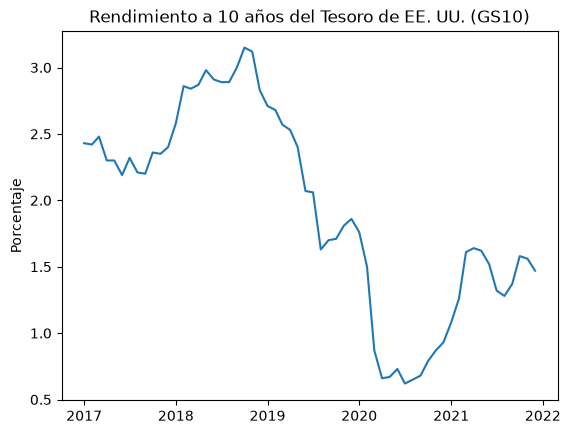

In [26]:
gs10 = pd.read_csv(DATOS / "u36-fred-gs10.csv", index_col="observation_date", parse_dates=True)

print(gs10.head(3))
print(gs10.shape)

plt.plot(gs10)
plt.title("Rendimiento a 10 años del Tesoro de EE. UU. (GS10)")
plt.ylabel("Porcentaje")
plt.show()

La curva reproduce la forma del gráfico del PDF: el rendimiento cae a mínimos hacia 2020 y se recupera en 2021.

**Referencia:** PDF parte 2, pág. 193

### 7.2 Banco Mundial: esperanza de vida por países

El PDF usa el módulo `wb` de `pandas_datareader` (no ejecutado aquí):

```python
import pandas_datareader as pdr
from pandas_datareader import wb

todos = pdr.wb.get_indicators()                    # lista de todos los indicadores
todos.iloc[:5, :2]                                 # los 5 primeros, columnas id y name

busqueda = pdr.wb.search("life expectancy")        # buscar un indicador por texto
paises = pdr.wb.get_countries()                    # datos de todos los países
paises.loc[0:5, ['name', 'capitalCity', 'iso2c']]

resultado = pdr.wb.download(indicator="SP.DYN.LE00.IN", start='1980', end='1999')
resultado = pdr.wb.download(indicator="SP.DYN.LE00.IN", start='1980', end='1999', country='all')
```

Por defecto `wb.download()` trae solo Canadá, Estados Unidos y México; con `country='all'` trae todos los países. El resultado tiene un índice de dos niveles (`country`, `year`) y una columna con el indicador. Con la copia local se obtiene la misma estructura:

In [27]:
vida = pd.read_csv(DATOS / "u36-esperanza-vida-bm.csv")

# Misma estructura que wb.download(): índice (country, year) y la columna del indicador
resultado = vida.set_index(["country", "year"])[["SP.DYN.LE00.IN"]].sort_index(ascending=[True, False])

# Comportamiento por defecto de wb.download(): Canadá, Estados Unidos y México
tres = resultado.loc[["Canada", "United States", "Mexico"]]
print(tres.head(5))
print()
print("Países y agregados con datos:", resultado.index.get_level_values("country").nunique())

              SP.DYN.LE00.IN
country year                
Canada  1999       78.839024
        1998       78.623659
        1997       78.412439
        1996       78.220244
        1995       77.977317

Países y agregados con datos: 265


**Nota sobre el PDF:** los valores del Banco Mundial se revisan con el tiempo; las cifras actuales difieren un poco de las que muestra el PDF (por ejemplo, Canadá en 1999 aparece con 78,89 en el PDF).

**Referencia:** PDF parte 2, págs. 195–200

### 7.3 Un paso más: qué país tiene la menor esperanza de vida cada año

Se reestructura el DataFrame con `reset_index()` y `pivot()`, de modo que cada fila sea un país y cada columna un año. Después, `DataFrame.idxmin(axis=0, skipna=True)` devuelve, para cada columna, la etiqueta de la fila donde está el mínimo.

In [28]:
datos_paises = resultado.reset_index()

pivot_result = datos_paises.pivot(index="country", columns="year", values="SP.DYN.LE00.IN")

print(pivot_result.shape)
pivot_result.iloc[:4, :5]

(265, 20)


year,1980,1981,1982,1983,1984
country,,,,,
Afghanistan,39.258000,39.406000,36.058000,36.517000,31.473000
Africa Eastern and Southern,49.816713,50.020493,50.290829,48.904096,48.997959
Africa Western and Central,46.691792,47.070561,47.368570,47.612811,47.789588
Albania,69.903000,70.145000,70.425000,70.705000,70.984000


In [29]:
result_country = pivot_result.idxmin(axis=0)
print(result_country.head(8))
print()
print(pivot_result.min().head(3))

year
1980    Timor-Leste
1981    Timor-Leste
1982    Timor-Leste
1983    Timor-Leste
1984    Afghanistan
1985    Afghanistan
1986    South Sudan
1987    South Sudan
dtype: str

year
1980    30.196
1981    31.247
1982    32.247
dtype: float64


**Nota sobre el PDF:** el texto de la diapositiva dice que se reestructura "con el índice de año y la columna de país", pero el código (y la salida) usa `index='country'` y `columns='year'`: filas = países, columnas = años. Por eso `idxmin(axis=0)` entrega un país por año. La variable se llama `result_contry` en la diapositiva (errata); aquí `result_country`.

**Ampliación (no está en el PDF):** los datos incluyen agregados regionales ("World", "Sub-Saharan Africa") además de países. Para comparar solo países conviene filtrar con la columna `iso3` o una lista de países.

**Para el quiz:** `axis=0` recorre las filas (resultado por columna); `axis=1` recorre las columnas (resultado por fila).

**Referencia:** PDF parte 2, págs. 201–204

## 8. Manipulación de filas, columnas y elementos

Para operar sobre un DataFrame hay que entender el concepto de **eje** (`axis`):

- `axis=0` (índice): trabaja en la dirección de las filas; el resultado aparece como una fila. Es como libros apilados unos sobre otros.
- `axis=1` (columnas): trabaja en la dirección de las columnas; el resultado aparece como una columna. Es como poner un libro al lado de otro.

Para practicar se usan los datos del ranking de universidades 2021 que se cargaron como JSON (aquí, las 20 filas de la reproducción).

In [30]:
rank = pd.read_json(DATOS / "u36-universities-ranking.json", orient="records")

rank.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ranking               20 non-null     int64  
 1   title                 20 non-null     str    
 2   location              20 non-null     str    
 3   number students       20 non-null     str    
 4   students staff ratio  20 non-null     float64
 5   perc intl students    20 non-null     str    
 6   gender ratio          20 non-null     str    
dtypes: float64(1), int64(1), str(5)
memory usage: 1.2 KB


**Nota sobre el PDF (pandas 3):** en `info()`, las columnas de texto aparecen como `str` en lugar de `object` (el PDF muestra `object`). Desde pandas 3 el tipo por defecto del texto es `str`.

In [31]:
rank.head()

,ranking,title,location,number students,students staff ratio,perc intl students,gender ratio
0,1,University of Oxford,United Kingdom,"20,774",11.1,41%,46 : 54
1,2,Stanford University,United States,"16,223",7.4,23%,44 : 56
2,3,Harvard University,United States,"21,261",9.3,25%,49 : 51
3,4,California Institute of Technology,United States,"2,238",6.3,33%,36 : 64
4,5,Massachusetts Institute of Technology,United States,"11,276",8.4,34%,39 : 61


**Referencia:** PDF parte 2, págs. 205–207

### 8.1 `drop()`: borrar filas y columnas

- Borrar filas: `df.drop(índices, axis=0, inplace=False)`.
- Borrar columnas: `df.drop(nombres_de_columna, axis=1, inplace=False)`.

Igual que en `rename()`, `inplace` decide si se modifica el objeto original; por defecto es `False` y el original no cambia. En pandas 3.1 `inplace` está en desuso, así que se reasigna el resultado.

In [32]:
sin_filas = rank.drop([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10], axis=0)
print("Filas antes:", len(rank), "| después:", len(sin_filas))
sin_filas.head(3)

Filas antes: 20 | después: 9


,ranking,title,location,number students,students staff ratio,perc intl students,gender ratio
11,12,Johns Hopkins University,United States,"16,432",4.4,27%,52 : 48
12,13,University of Pennsylvania,United States,"20,771",6.4,21%,52 : 48
13,14,ETH Zurich,Switzerland,"19,632",13.1,40%,32 : 68


In [33]:
sin_columnas = rank.drop(["students staff ratio", "gender ratio"], axis=1)
print("Columnas antes:", list(rank.columns))
print("Columnas después:", list(sin_columnas.columns))
sin_columnas.head(3)

Columnas antes: ['ranking', 'title', 'location', 'number students', 'students staff ratio', 'perc intl students', 'gender ratio']
Columnas después: ['ranking', 'title', 'location', 'number students', 'perc intl students']


,ranking,title,location,number students,perc intl students
0,1,University of Oxford,United Kingdom,"20,774",41%
1,2,Stanford University,United States,"16,223",23%
2,3,Harvard University,United States,"21,261",25%


**Nota sobre el PDF:** la diapositiva 208 describe el borrado de columnas con `axis=0`, pero el código de las diapositivas siguientes usa `axis=1`, que es lo correcto: las columnas se borran con `axis=1`. El PDF escribe además `inplace=False`; como es el valor por defecto y en pandas 3.1 el parámetro `inplace` está en desuso, aquí se omite. En la diapositiva 209 el resultado tiene 1515 filas porque el archivo original tiene 1526; la reproducción de este notebook tiene 20.

**Error común:** olvidar `axis=1` al borrar columnas. Con `axis=0` pandas busca una **fila** con ese nombre y lanza `KeyError`.

In [34]:
try:
    rank.drop(["gender ratio"], axis=0)
except KeyError as error:
    print("KeyError:", error)

KeyError: "['gender ratio'] not found in axis"


**Referencia:** PDF parte 2, págs. 208–211

### 8.2 Seleccionar filas: `loc` y `iloc`

Hay dos formas principales de seleccionar filas:

- `.loc[]`: por **etiqueta** del índice.
- `.iloc[]`: por **posición** entera, empezando en 0.

In [35]:
df = pd.DataFrame({"Nombre": ["Ana", "Luis", "Carla"], "Edad": [23, 30, 27]}, index=["a", "b", "c"])

print(df.loc["b"])      # Selección por etiqueta: fila con índice 'b'
print()
print(df.iloc[1])       # Selección por posición: segunda fila (posición 1)

Nombre    Luis
Edad        30
Name: b, dtype: object

Nombre    Luis
Edad        30
Name: b, dtype: object


Con los datos de universidades: `iloc[1:10]` toma las posiciones 1 a 9 (el extremo final no se incluye), y se guarda en un DataFrame nuevo.

In [36]:
index_position = rank.iloc[1:10]

index_position

,ranking,title,location,number students,students staff ratio,perc intl students,gender ratio
1,2,Stanford University,United States,"16,223",7.4,23%,44 : 56
2,3,Harvard University,United States,"21,261",9.3,25%,49 : 51
3,4,California Institute of Technology,United States,"2,238",6.3,33%,36 : 64
4,5,Massachusetts Institute of Technology,United States,"11,276",8.4,34%,39 : 61
5,6,University of Cambridge,United Kingdom,"19,370",11.0,38%,47 : 53
6,7,"University of California, Berkeley",United States,"39,918",19.8,17%,51 : 49
7,8,Yale University,United States,"12,910",6.0,20%,50 : 50
8,9,Princeton University,United States,"8,091",8.0,23%,46 : 54
9,10,The University of Chicago,United States,"14,292",5.9,31%,46 : 54


Para practicar `loc`, se cambian los índices enteros por etiquetas de texto. El PDF recomienda **copiar** el DataFrame antes (`copy()`) y trabajar sobre la copia: `rename(..., inplace=True)` sobre un objeto que es una porción de otro puede producir avisos o errores por la gestión de memoria.

In [37]:
df = index_position.copy()

df.rename(index={1: "a", 2: "b", 3: "c", 4: "d", 5: "e", 6: "f", 7: "g", 8: "h", 9: "i"}, inplace=True)

df

/var/folders/xp/xx59bb5s1n31zc4kh2lnljyc0000gn/T/ipykernel_25897/1155641482.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(index={1: "a", 2: "b", 3: "c", 4: "d", 5: "e", 6: "f", 7: "g", 8: "h", 9: "i"}, inplace=True)


,ranking,title,location,number students,students staff ratio,perc intl students,gender ratio
a,2,Stanford University,United States,"16,223",7.4,23%,44 : 56
b,3,Harvard University,United States,"21,261",9.3,25%,49 : 51
c,4,California Institute of Technology,United States,"2,238",6.3,33%,36 : 64
d,5,Massachusetts Institute of Technology,United States,"11,276",8.4,34%,39 : 61
e,6,University of Cambridge,United Kingdom,"19,370",11.0,38%,47 : 53
f,7,"University of California, Berkeley",United States,"39,918",19.8,17%,51 : 49
g,8,Yale University,United States,"12,910",6.0,20%,50 : 50
h,9,Princeton University,United States,"8,091",8.0,23%,46 : 54
i,10,The University of Chicago,United States,"14,292",5.9,31%,46 : 54


In [38]:
index_label = df.loc[["a", "b"]]

index_label

,ranking,title,location,number students,students staff ratio,perc intl students,gender ratio
a,2,Stanford University,United States,"16,223",7.4,23%,44 : 56
b,3,Harvard University,United States,"21,261",9.3,25%,49 : 51


**Nota sobre el PDF (pandas 3):** con la *copia en escritura* (copy-on-write) de pandas 3, `iloc[1:10]` ya devuelve un objeto independiente: modificarlo nunca altera `rank`. Aun así, `copy()` deja clara la intención y sigue siendo buena práctica.

**Clave:** `loc` usa etiquetas y **incluye** el extremo final (`df.loc["a":"c"]` trae a, b y c); `iloc` usa posiciones y **excluye** el extremo final.

**Referencia:** PDF parte 2, págs. 212–217

### 8.3 Seleccionar columnas

- Una columna: `df["nombre"]` o `df.nombre` (esta última solo sirve si el nombre es una cadena válida como identificador, sin espacios).
- Varias columnas: se pasa una **lista** dentro de los corchetes, `df[["col1", "col2"]]`.

`df["title"]` devuelve una **Serie**; `df[["title"]]` (con lista) devuelve un **DataFrame** de una columna.

In [39]:
a = index_position.title
b = index_position[["title"]]

print(type(a))
print(a)
print()
print(type(b))
print(b)

<class 'pandas.Series'>
1                      Stanford University
2                       Harvard University
3       California Institute of Technology
4    Massachusetts Institute of Technology
5                  University of Cambridge
6       University of California, Berkeley
7                          Yale University
8                     Princeton University
9                The University of Chicago
Name: title, dtype: str

<class 'pandas.DataFrame'>
                                   title
1                    Stanford University
2                     Harvard University
3     California Institute of Technology
4  Massachusetts Institute of Technology
5                University of Cambridge
6     University of California, Berkeley
7                        Yale University
8                   Princeton University
9              The University of Chicago


In [40]:
c = index_position[["title", "location", "students staff ratio"]]

c

,title,location,students staff ratio
1,Stanford University,United States,7.4
2,Harvard University,United States,9.3
3,California Institute of Technology,United States,6.3
4,Massachusetts Institute of Technology,United States,8.4
5,University of Cambridge,United Kingdom,11.0
6,"University of California, Berkeley",United States,19.8
7,Yale University,United States,6.0
8,Princeton University,United States,8.0
9,The University of Chicago,United States,5.9


**Nota sobre el PDF:** la diapositiva 222 escribe `index_position.gender ratio` como ejemplo de acceso por atributo. Eso es un error de sintaxis, porque el nombre tiene un espacio. Para esa columna hay que usar `index_position["gender ratio"]` (Serie) o `index_position[["gender ratio"]]` (DataFrame).

**Error común:** `df["a", "b"]` (sin lista interna) busca una columna llamada con la tupla `("a", "b")` y falla. Las varias columnas van dentro de una lista: `df[["a", "b"]]`.

**Referencia:** PDF parte 2, págs. 218–222

### 8.4 Seleccionar un elemento (una celda)

Se indica la posición como coordenadas [fila, columna]:

- `df.loc[nombre_fila, nombre_columna]`: por etiquetas.
- `df.iloc[número_fila, número_columna]`: por posiciones.

Con `iloc` también se pueden pedir rectángulos con rebanadas: `df.iloc[0:1, 0:2]` toma la primera fila y las dos primeras columnas; `df.iloc[0:4, 3:]` toma las cuatro primeras filas y todas las columnas desde la cuarta.

In [41]:
df = rank.iloc[1:10]

d = df.iloc[7, 1]      # fila de posición 7, columna de posición 1
print(d)
print(df.loc[8, "title"])   # la misma celda por etiquetas: etiqueta de fila 8, columna "title"

Princeton University
Princeton University


In [42]:
e = df.iloc[0:1, 0:2]
f = df.iloc[0:4, 3:]
print(e)
print()
print(f)

   ranking                title
1        2  Stanford University

  number students  students staff ratio perc intl students gender ratio
1          16,223                   7.4                23%      44 : 56
2          21,261                   9.3                25%      49 : 51
3           2,238                   6.3                33%      36 : 64
4          11,276                   8.4                34%      39 : 61


**Nota sobre el PDF:** la diapositiva 224 rotula la celda como `df[7,1]`, que no es una sintaxis válida de pandas (`df[7, 1]` lanza `KeyError`). La forma correcta es `df.iloc[7, 1]`.

**Para el quiz:** `loc` = etiquetas (extremo incluido); `iloc` = posiciones (extremo excluido).

**Referencia:** PDF parte 2, págs. 223–225

## 9. Codifiquemos: la misión con datos de Spotify

El PDF resuelve la misión en seis pasos. Esta sección sigue esos pasos, pero con un conjunto de datos distinto, por el motivo que se explica a continuación.

**Primer paso — bibliotecas y datos.** Se necesitan `pandas` (DataFrames), `matplotlib` (visualización) y `seaborn` (visualización de datos, usada para el mapa de calor). Después se busca el conjunto de datos y se crea el DataFrame con `pd.read_csv()`. El PDF usa `spotify_global_2019_most_streamed_tracks_audio_features.csv` de Kaggle (1717 filas y 24 columnas: `Country`, `Rank`, `Track_id`, `Streams`, `Track Name`, `Artist`, `URL`, `Artist_popularity`, `acousticness`, `danceability`, `energy`, `tempo`...).

**Nota sobre los datos (ampliación, no está en el PDF):** ese archivo de Kaggle exige una cuenta para descargarlo y no se encontró una copia pública verificable. Para no inventar datos, se usa en su lugar un conjunto **público y real con la misma idea**: *Top Hits Spotify from 2000-2019* (2000 canciones que fueron éxitos entre 1998 y 2020, con las características de audio que entrega Spotify). Se obtuvo del espejo `osanseviero/top-hits-spotify` en Hugging Face (archivo `songs_normalize.csv`, sin modificar) y se guardó como `../datos/u36-spotify-top-hits.csv` (253 KB). Equivalencias:

| PDF (Kaggle, 2019 global) | Este notebook (Top Hits) |
|---|---|
| `Artist` | `artist` |
| `Track Name` | `song` |
| `Artist_popularity` (popularidad del artista) | `popularity` (popularidad de la **canción**, 0 a 100) |
| `Streams`, `Rank`, `Country` | no existen |
| `tempo`, `danceability`, `energy` | `tempo`, `danceability`, `energy` (mismos nombres) |

Por eso los **resultados numéricos no coinciden** con los del PDF (el PDF obtiene a Post Malone con 45 canciones), pero el código y el método son los mismos.

In [43]:
song = pd.read_csv(DATOS / "u36-spotify-top-hits.csv")

song.head(10)

,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.30000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.01030,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.17300,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.02630,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.04080,0.001040,0.0845,0.879,172.656,pop
5,Sisqo,Thong Song,253733,True,1999,69,0.706,0.888,2,-6.959,1,0.0654,0.11900,0.000096,0.0700,0.714,121.549,"hip hop, pop, R&B"
6,Eminem,The Real Slim Shady,284200,True,2000,86,0.949,0.661,5,-4.244,0,0.0572,0.03020,0.000000,0.0454,0.760,104.504,hip hop
7,Robbie Williams,Rock DJ,258560,False,2000,68,0.708,0.772,7,-4.264,1,0.0322,0.02670,0.000000,0.4670,0.861,103.035,"pop, rock"
8,Destiny's Child,Say My Name,271333,False,1999,75,0.713,0.678,5,-3.525,0,0.1020,0.27300,0.000000,0.1490,0.734,138.009,"pop, R&B"
9,Modjo,Lady - Hear Me Tonight,307153,False,2001,77,0.720,0.808,6,-5.627,1,0.0379,0.00793,0.029300,0.0634,0.869,126.041,Dance/Electronic


In [44]:
song.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   artist            2000 non-null   str    
 1   song              2000 non-null   str    
 2   duration_ms       2000 non-null   int64  
 3   explicit          2000 non-null   bool   
 4   year              2000 non-null   int64  
 5   popularity        2000 non-null   int64  
 6   danceability      2000 non-null   float64
 7   energy            2000 non-null   float64
 8   key               2000 non-null   int64  
 9   loudness          2000 non-null   float64
 10  mode              2000 non-null   int64  
 11  speechiness       2000 non-null   float64
 12  acousticness      2000 non-null   float64
 13  instrumentalness  2000 non-null   float64
 14  liveness          2000 non-null   float64
 15  valence           2000 non-null   float64
 16  tempo             2000 non-null   float64
 17  genre 

In [45]:
song.describe()

,duration_ms,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,228748.124500,2009.49400,59.872500,0.667438,0.720366,5.378000,-5.512434,0.553500,0.103568,0.128955,0.015226,0.181216,0.551690,120.122558
std,39136.569008,5.85996,21.335577,0.140416,0.152745,3.615059,1.933482,0.497254,0.096159,0.173346,0.087771,0.140669,0.220864,26.967112
min,113000.000000,1998.00000,0.000000,0.129000,0.054900,0.000000,-20.514000,0.000000,0.023200,0.000019,0.000000,0.021500,0.038100,60.019000
25%,203580.000000,2004.00000,56.000000,0.581000,0.622000,2.000000,-6.490250,0.000000,0.039600,0.014000,0.000000,0.088100,0.386750,98.985750
50%,223279.500000,2010.00000,65.500000,0.676000,0.736000,6.000000,-5.285000,1.000000,0.059850,0.055700,0.000000,0.124000,0.557500,120.021500
75%,248133.000000,2015.00000,73.000000,0.764000,0.839000,8.000000,-4.167750,1.000000,0.129000,0.176250,0.000068,0.241000,0.730000,134.265500
max,484146.000000,2020.00000,89.000000,0.975000,0.999000,11.000000,-0.276000,1.000000,0.576000,0.976000,0.985000,0.853000,0.973000,210.851000


En el PDF, `head(10)` muestra solo las primeras filas, `info()` informa de 1717 filas y 24 columnas, y `describe()` entrega la distribución de datos de las columnas numéricas. Aquí el DataFrame tiene 2000 filas y 18 columnas (en pandas 3, `explicit` es booleana y el texto es `str`).

**Referencia:** PDF parte 2, págs. 227–230

**Paso 2 — seleccionar las columnas necesarias.** Se eligen varias columnas y se guardan en un nuevo DataFrame `df`. Se incluye la columna `year` para poder ubicar las canciones en el tiempo.

**Ampliación (no está en el PDF):** el conjunto Top Hits contiene canciones repetidas (la misma canción aparece más de una vez). Si no se eliminan, un artista suma canciones de más al contarlas. Se descartan con `drop_duplicates()`, indicando que dos filas son la misma canción si coinciden en artista y título.

In [46]:
df = song[["artist", "song", "year", "popularity", "tempo", "danceability", "energy"]]

print("Filas repetidas (mismo artista y canción):", df.duplicated(["artist", "song"]).sum())
df = df.drop_duplicates(["artist", "song"])
print("Filas después de quitar repetidas:", len(df))
df.head()

Filas repetidas (mismo artista y canción): 74
Filas después de quitar repetidas: 1926


,artist,song,year,popularity,tempo,danceability,energy
0,Britney Spears,Oops!...I Did It Again,2000,77,95.053,0.751,0.834
1,blink-182,All The Small Things,1999,79,148.726,0.434,0.897
2,Faith Hill,Breathe,1999,66,136.859,0.529,0.496
3,Bon Jovi,It's My Life,2000,78,119.992,0.551,0.913
4,*NSYNC,Bye Bye Bye,2000,65,172.656,0.614,0.928


**Referencia:** PDF parte 2, pág. 231

**Paso 3 — filtrar y contar.** El PDF filtra las filas con `Artist_popularity` mayor que 90 (el texto dice 95, pero el código usa `> 90`; el propio PDF recomienda ajustar el umbral según la estructura de los datos). El filtro usa un operador lógico sobre los valores de una columna y se puede combinar con varios operadores. Aquí se usa `popularity >= 80`, porque la popularidad de una canción rara vez supera 90.

Después, `value_counts()` cuenta los valores únicos de la columna del artista y devuelve una **Serie** ordenada de mayor a menor.

In [47]:
pop_song = df[df["popularity"] >= 80]
print(pop_song.shape)
pop_song.head()

(126, 7)


,artist,song,year,popularity,tempo,danceability,energy
6,Eminem,The Real Slim Shady,2000,86,104.504,0.949,0.661
19,Dr. Dre,The Next Episode,1999,82,95.295,0.922,0.909
20,Linkin Park,In the End,2000,83,105.143,0.556,0.864
102,Eminem,Stan,2000,83,80.063,0.780,0.768
130,Outkast,Ms. Jackson,2000,82,94.948,0.843,0.806


In [48]:
rank_artistas = pop_song["artist"].value_counts()

print(rank_artistas.head())
print()
print(type(rank_artistas))

artist
Eminem           5
Coldplay         4
Post Malone      4
Pitbull          3
One Direction    3
Name: count, dtype: int64

<class 'pandas.Series'>


`unique()` devuelve todos los valores únicos de la columna (ampliación: `nunique()` cuenta cuántos hay):

In [49]:
print(pop_song["artist"].unique()[:12])
print("Artistas distintos:", pop_song["artist"].nunique())

<StringArray>
[               'Eminem',               'Dr. Dre',           'Linkin Park',
               'Outkast', 'Red Hot Chili Peppers',               '50 Cent',
                 'Usher',        'Britney Spears',            'Kanye West',
              'Gorillaz',               'Shakira',         'Nelly Furtado']
Length: 12, dtype: str
Artistas distintos: 85


**Nota sobre el PDF:** en pandas 3 la Serie de `value_counts()` se llama `count` y su índice se llama `artist` (en versiones antiguas el nombre de la Serie era el de la columna, como muestra la diapositiva: `Name: Artist`). No cambia el uso.

**Referencia:** PDF parte 2, págs. 232–235

**Paso 4 — ¿es popular un artista concreto?** El PDF pregunta si BTS es realmente popular. Primero se comprueba si el artista existe en el conjunto: `'BTS' in rank` pregunta si el nombre está en el **índice** de la Serie de conteos (no en los valores). Luego se filtra el DataFrame por ese artista.

In [50]:
artista = "BTS"

print(artista in rank_artistas)                # ¿aparece entre los artistas populares?
print(artista in set(df["artist"]))            # ¿existe en todo el conjunto?

bts = df[df["artist"] == artista]
print(bts.shape)
bts

False
True
(1, 7)


,artist,song,year,popularity,tempo,danceability,energy
1970,BTS,Boy With Luv (feat. Halsey),2019,35,119.991,0.645,0.862


En este conjunto, BTS no aparece en el filtro de popularidad alta (`False`) pero sí existe con una canción en el conjunto completo. El resultado depende de los datos: con el archivo de Kaggle del PDF, BTS tiene 11 canciones.

**Error común:** `"BTS" in serie` consulta el **índice** de la Serie. En un DataFrame, `"BTS" in df["artist"]` también consulta el índice (números), no los valores; para los valores se usa `df["artist"].isin(["BTS"])` o `(df["artist"] == "BTS").any()`.

**Referencia:** PDF parte 2, págs. 236–238

**Paso 5 — lista de reproducción del artista con más canciones.** En el PDF, Post Malone tiene 45 canciones en el conjunto. Aquí se toma el artista que encabeza `value_counts()`, se filtran sus canciones y se reinicia el índice con `reset_index(drop=True)` para que vuelva a empezar en 0 (con `drop=True` el índice anterior se descarta en lugar de pasar a ser una columna).

In [51]:
mejor_artista = rank_artistas.index[0]
print("Artista con más canciones populares:", mejor_artista, "-", rank_artistas.iloc[0], "canciones")

play_list = pop_song[pop_song["artist"] == mejor_artista]
lista = play_list.reset_index(drop=True)
lista

Artista con más canciones populares: Eminem - 5 canciones


,artist,song,year,popularity,tempo,danceability,energy
0,Eminem,The Real Slim Shady,2000,86,104.504,0.949,0.661
1,Eminem,Stan,2000,83,80.063,0.780,0.768
2,Eminem,Without Me,2002,87,112.238,0.908,0.669
3,Eminem,'Till I Collapse,2002,85,171.447,0.548,0.847
4,Eminem,Love The Way You Lie,2010,81,86.989,0.749,0.925


**Nota sobre el PDF:** el código de la diapositiva pasa `inplace=False` a `reset_index`, que es el valor por defecto; basta con reasignar. 

**Referencia:** PDF parte 2, págs. 239–240

**Paso 6 — relación entre el tempo y la popularidad.** Un **diagrama de dispersión** representa la relación entre dos variables x e y: cada fila es un punto (x, y) en el plano. Se puede ver si una variable tiende a aumentar (o disminuir) cuando aumenta la otra. La relación es fuerte o débil según qué tan cerca están los puntos de una recta.

- **Correlación positiva:** si x sube, y tiende a subir (más inversión en marketing, más ventas).
- **Correlación negativa:** si x sube, y tiende a bajar (más producción de un producto, menor precio).
- **No confundir:** que la correlación sea positiva o negativa no dice **qué tan fuerte** es. Eso lo indica la cercanía de los puntos a la recta.

El gráfico se traza con `plt.scatter()`.

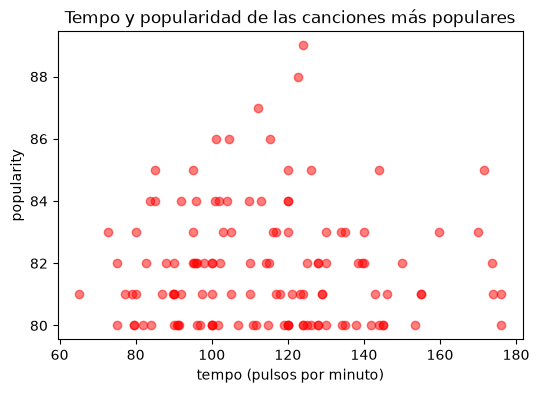

In [52]:
x = pop_song["tempo"]
y = pop_song["popularity"]

plt.figure(figsize=(6, 4))
plt.scatter(x, y, color="red", alpha=0.5)
plt.xlabel("tempo (pulsos por minuto)")
plt.ylabel("popularity")
plt.title("Tempo y popularidad de las canciones más populares")
plt.show()

A simple vista no hay una correlación clara entre las dos variables: los puntos forman una nube sin dirección.

**Nota sobre el PDF:** la diapositiva 243 grafica `energy` en x y `Rank` en y, aunque el texto de la misión habla de tempo y popularidad. El código de arriba grafica lo que dice el enunciado: tempo contra popularidad.

El coeficiente de correlación se calcula con `DataFrame.corr(method="pearson")`: la correlación por pares de columnas, ignorando los valores `NA`/nulos. Los métodos son `pearson` (estándar, por defecto), `kendall` (Kendall Tau) y `spearman` (correlación de rangos). El resultado es un DataFrame que se interpreta así:

- Cerca de **1**: ambas variables aumentan juntas.
- Cerca de **-1**: cuando una aumenta, la otra disminuye.
- Cerca de **0**: no hay relación entre ellas.

In [53]:
cor = pop_song[["popularity", "tempo", "danceability", "energy"]].corr(method="pearson")
cor

,popularity,tempo,danceability,energy
popularity,1.000000,-0.007243,-0.035676,-0.195164
tempo,-0.007243,1.000000,-0.095533,0.105553
danceability,-0.035676,-0.095533,1.000000,0.100605
energy,-0.195164,0.105553,0.100605,1.000000


**Nota sobre el PDF (pandas 3):** el PDF llama a `pop_song.corr()` sobre todo el DataFrame y comenta que "los datos de tipo cadena se restan naturalmente". En pandas 2 y 3 eso ya no ocurre: con columnas de texto, `corr()` lanza `ValueError` si no se indica `numeric_only=True`. Por eso aquí se seleccionan las columnas numéricas antes (también se podría escribir `pop_song.corr(numeric_only=True)`).

In [54]:
try:
    pop_song.corr()
except ValueError as error:
    print("ValueError:", str(error)[:70], "...")

print()
print(pop_song.corr(numeric_only=True).round(3).loc[["popularity"], ["tempo", "danceability", "energy"]])

ValueError: could not convert string to float: 'Eminem' ...

            tempo  danceability  energy
popularity -0.007        -0.036  -0.195


Ninguna variable está cerca de 1 ni de -1; el tempo y la popularidad tienen una correlación cercana a 0, es decir, **no hay relación apreciable**. El PDF llega a la misma conclusión con sus datos: el tempo parece tener el menor efecto.

La matriz de correlación se visualiza como mapa de calor, con `plt.matshow()` y una barra de colores, o con `sns.heatmap()` y `annot=True` para escribir el valor en cada celda:

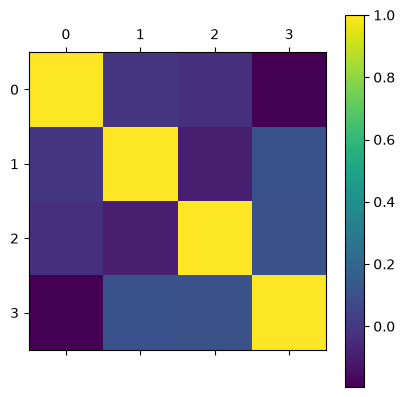

In [55]:
plt.matshow(cor)
plt.colorbar()
plt.show()

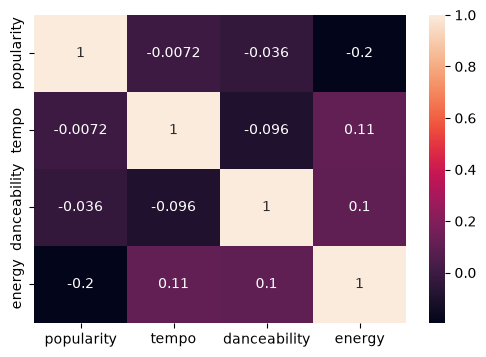

In [56]:
plt.figure(figsize=(6, 4))
sns.heatmap(cor, annot=True)
plt.show()

**Clave:** correlación no implica causalidad; un valor cercano a 0 solo indica que no hay una relación lineal apreciable.

**Referencia:** PDF parte 2, págs. 241–247

## 10. Ampliación: editar filas y columnas, aritmética, estadísticas y gráficos

**Ampliación (no está en el PDF):** esta sección cubre lo que el contexto del docente lista como objetivos (editar filas y columnas, aritmética, estadísticas descriptivas básicas y gráficos de líneas, de barras y de dispersión) y que el PDF solo menciona de forma indirecta (pág. 146: "añadir y combinar filas, columnas y elementos de datos"). Todo el contenido de esta sección es adicional al PDF.

Se parte de un DataFrame pequeño de ventas:

In [57]:
ventas = pd.DataFrame(
    {
        "producto": ["arroz", "leche", "pan", "huevos", "café"],
        "precio": [1.20, 0.95, 0.40, 2.10, 4.50],
        "cantidad": [30, 45, 120, 25, 12],
    },
    index=["p1", "p2", "p3", "p4", "p5"],
)
ventas

,producto,precio,cantidad
p1,arroz,1.20,30
p2,leche,0.95,45
p3,pan,0.40,120
p4,huevos,2.10,25
p5,café,4.50,12


### 10.1 Agregar y modificar columnas

Asignar a una columna nueva la crea; asignar a una existente la modifica. Las operaciones aritméticas entre columnas se aplican **elemento a elemento**, alineadas por el índice.

In [58]:
ventas["total"] = ventas["precio"] * ventas["cantidad"]      # columna nueva (aritmética entre columnas)
ventas["precio"] = ventas["precio"] * 1.10                   # modifica una columna existente (+10 %)
ventas["precio"] = ventas["precio"].round(2)
ventas["categoria"] = "alimentos"                            # un valor escalar se repite en todas las filas

ventas

,producto,precio,cantidad,total,categoria
p1,arroz,1.32,30,36.00,alimentos
p2,leche,1.04,45,42.75,alimentos
p3,pan,0.44,120,48.00,alimentos
p4,huevos,2.31,25,52.50,alimentos
p5,café,4.95,12,54.00,alimentos


### 10.2 Agregar, modificar y borrar filas

- Con `loc` y una etiqueta nueva se agrega una fila; con una etiqueta existente se modifica.
- `pd.concat([df1, df2])` une DataFrames por filas.
- `drop()` (visto en 8.1) borra filas.

In [59]:
ventas.loc["p6"] = ["té", 3.00, 20, 60.0, "alimentos"]       # fila nueva
ventas.loc["p3", "cantidad"] = 150                           # modifica una celda
ventas.loc["p3", "total"] = ventas.loc["p3", "precio"] * ventas.loc["p3", "cantidad"]

extra = pd.DataFrame(
    {"producto": ["sal"], "precio": [0.60], "cantidad": [40], "total": [24.0], "categoria": ["alimentos"]},
    index=["p7"],
)
ventas = pd.concat([ventas, extra])                          # une por filas
ventas

,producto,precio,cantidad,total,categoria
p1,arroz,1.32,30,36.00,alimentos
p2,leche,1.04,45,42.75,alimentos
p3,pan,0.44,150,66.00,alimentos
p4,huevos,2.31,25,52.50,alimentos
p5,café,4.95,12,54.00,alimentos
p6,té,3.00,20,60.00,alimentos
p7,sal,0.60,40,24.00,alimentos


**Nota sobre pandas 3:** `DataFrame.append()`, que se usaba para añadir filas, **fue eliminado** (en pandas 2.0). La forma actual es `pd.concat()`. Además, con *copy-on-write* la "asignación encadenada" ya no modifica el original: `ventas["precio"][0] = 5` o `ventas[ventas["cantidad"] > 20]["precio"] = 0` no cambian `ventas`; hay que usar una sola operación `loc`, como arriba (`ventas.loc[condición, "precio"] = 0`).

### 10.3 Aritmética y estadísticas descriptivas

In [60]:
print("Suma de totales:  ", round(ventas["total"].sum(), 2))
print("Precio medio:     ", round(ventas["precio"].mean(), 2))
print("Mediana cantidad: ", ventas["cantidad"].median())
print("Producto más caro:", ventas.loc[ventas["precio"].idxmax(), "producto"])
print()
print(ventas[["precio", "cantidad", "total"]].agg(["min", "max", "mean", "std"]).round(2))
print()
print(ventas[["precio", "cantidad", "total"]].describe().round(2))

Suma de totales:   335.25
Precio medio:      1.95
Mediana cantidad:  30.0
Producto más caro: café

      precio  cantidad  total
min     0.44     12.00  24.00
max     4.95    150.00  66.00
mean    1.95     46.00  47.89
std     1.61     47.23  14.56

       precio  cantidad  total
count    7.00      7.00   7.00
mean     1.95     46.00  47.89
std      1.61     47.23  14.56
min      0.44     12.00  24.00
25%      0.82     22.50  39.38
50%      1.32     30.00  52.50
75%      2.66     42.50  57.00
max      4.95    150.00  66.00


Las funciones de estadística (`sum`, `mean`, `median`, `std`, `min`, `max`, `idxmin`, `idxmax`) operan por columna (`axis=0`, el valor por defecto) o por fila (`axis=1`). `describe()` las resume y `corr()` mide la relación entre columnas.

### 10.4 Gráficos con matplotlib: líneas, barras y dispersión

Un DataFrame se grafica con `df.plot(kind=...)` (que usa matplotlib por debajo) o directamente con `plt`.

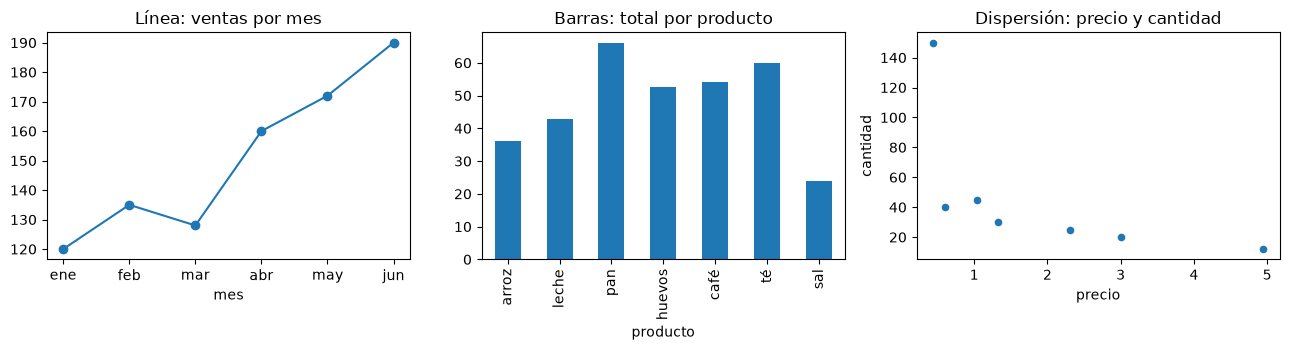

In [61]:
mensual = pd.DataFrame(
    {"mes": ["ene", "feb", "mar", "abr", "may", "jun"], "ventas": [120, 135, 128, 160, 172, 190]}
).set_index("mes")

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6))

mensual.plot(kind="line", marker="o", ax=ejes[0], legend=False, title="Línea: ventas por mes")
ventas.set_index("producto")["total"].plot(kind="bar", ax=ejes[1], title="Barras: total por producto")
ventas.plot(kind="scatter", x="precio", y="cantidad", ax=ejes[2], title="Dispersión: precio y cantidad")

for eje in ejes:
    eje.set_xlabel(eje.get_xlabel())
plt.tight_layout()
plt.show()

**Clave:** línea para evolución en el tiempo, barras para comparar categorías, dispersión para la relación entre dos variables numéricas.

**Error común:** `df.plot()` sin `kind` grafica **todas** las columnas numéricas contra el índice; hay que seleccionar las columnas o indicar `x` e `y`.

## Proyecto de la unidad

**Problema (PDF, pág. 149):** importar datos externos para encontrar y ordenar los elementos de datos que se desean. Con el conjunto de canciones de Spotify hay que:

1. Averiguar qué artista tiene las canciones más populares.
2. Comprobar con un gráfico de dispersión si el tempo se relaciona con la popularidad.
3. Crear una lista de canciones del artista favorito y compartirla como archivo Excel.

**Plan de programación (los seis pasos del PDF, págs. 227–247):**

1. Importar las bibliotecas y cargar el CSV en un DataFrame.
2. Seleccionar solo las columnas necesarias.
3. Filtrar por popularidad alta y contar las canciones por artista con `value_counts()`.
4. Comprobar si un artista concreto existe y filtrar sus canciones.
5. Crear la lista de reproducción del artista con más canciones y reiniciar el índice.
6. Estudiar la relación tempo-popularidad con el gráfico de dispersión y `corr()`.

El código final reúne los pasos en una función; la lista de reproducción se guarda en Excel en la carpeta temporal.

In [62]:
def mision_spotify(ruta_csv, umbral=80, artista_favorito=None, carpeta_salida=TMP):
    """Resuelve la misión de la unidad y devuelve un resumen con los resultados principales."""
    # Pasos 1 y 2: cargar el CSV y quedarse con las columnas necesarias
    song = pd.read_csv(ruta_csv)
    df = song[["artist", "song", "year", "popularity", "tempo", "danceability", "energy"]]
    df = df.drop_duplicates(["artist", "song"])    # el conjunto repite algunas canciones

    # Paso 3: filtrar por popularidad y contar canciones por artista
    pop_song = df[df["popularity"] >= umbral]
    rank = pop_song["artist"].value_counts()
    mejor_artista = rank.index[0]

    # Paso 4: ¿existe el artista favorito y cuántas canciones tiene?
    if artista_favorito is None:
        artista_favorito = mejor_artista
    canciones_favorito = df[df["artist"] == artista_favorito]

    # Paso 5: lista de reproducción del artista con más canciones, guardada en Excel
    play_list = pop_song[pop_song["artist"] == mejor_artista].reset_index(drop=True)
    ruta_excel = Path(carpeta_salida) / f"lista-{mejor_artista.lower().replace(' ', '-')}.xlsx"
    play_list.to_excel(ruta_excel, index=False)

    # Paso 6: correlación entre tempo y popularidad
    correlacion = pop_song["tempo"].corr(pop_song["popularity"])

    return {
        "canciones_populares": len(pop_song),
        "mejor_artista": mejor_artista,
        "canciones_mejor_artista": int(rank.iloc[0]),
        "canciones_favorito": len(canciones_favorito),
        "excel": ruta_excel,
        "correlacion_tempo_popularidad": round(float(correlacion), 3),
    }


resumen = mision_spotify(DATOS / "u36-spotify-top-hits.csv", umbral=80, artista_favorito="BTS")
for clave, valor in resumen.items():
    print(f"{clave}: {valor}")

# Se comprueba que el Excel se puede volver a leer (lo que haría un compañero de estudio)
print()
print(pd.read_excel(resumen["excel"]).head())

canciones_populares: 126
mejor_artista: Eminem
canciones_mejor_artista: 5
canciones_favorito: 1
excel: /var/folders/xp/xx59bb5s1n31zc4kh2lnljyc0000gn/T/u36-j26xsefg/lista-eminem.xlsx
correlacion_tempo_popularidad: -0.007

   artist                  song  year  popularity    tempo  danceability  \
0  Eminem   The Real Slim Shady  2000          86  104.504         0.949   
1  Eminem                  Stan  2000          83   80.063         0.780   
2  Eminem            Without Me  2002          87  112.238         0.908   
3  Eminem      'Till I Collapse  2002          85  171.447         0.548   
4  Eminem  Love The Way You Lie  2010          81   86.989         0.749   

   energy  
0   0.661  
1   0.768  
2   0.669  
3   0.847  
4   0.925  


**Resultado esperado:** el artista con más canciones populares se obtiene de `value_counts()`; la correlación entre tempo y popularidad está cerca de 0, de modo que el tempo no explica la popularidad; y el Excel con la lista de reproducción queda guardado y se puede leer de nuevo con `pd.read_excel()`.

**Referencia:** PDF parte 2, págs. 149 y 227–247

### Programación en pareja (págs. 249–251)

Las diapositivas 249 y 250 son material general sobre la **programación en pareja** (aparecen en español e inglés superpuestos): preparar la actividad con pautas, mecanismos y planes de contingencia (por ejemplo, turnarse para "manejar el mouse" y qué hacer si un compañero falta); emparejar a estudiantes de habilidades similares, no necesariamente iguales; ofrecer incentivos; y evitar las trampas diseñando evaluaciones individuales y explicando qué conductas se consideran trampa. Un entorno de aprendizaje colaborativo no es "divide y vencerás": cada integrante participa en todo el proyecto.

**Q1 (pág. 251):** en el conjunto de Spotify hay otros valores de columna además del artista, el rango y la popularidad. Se pide comentar con los compañeros la posibilidad de crear **listas de reproducción especiales** usando distintas columnas. Ejemplo del PDF: una lista solo con música alegre, usando la columna `tempo` para elegir un tempo adecuado.

**Consejo del PDF:** guardar la lista de reproducción como archivo Excel con `DataFrame.to_excel()` y compartirla.

Una posible solución con las columnas `tempo`, `energy` y `danceability` (el PDF solo sugiere `tempo`; combinar columnas es una ampliación):

In [63]:
song = pd.read_csv(DATOS / "u36-spotify-top-hits.csv")

# Música alegre y bailable: tempo rápido, energía y bailabilidad altas
alegre = song.drop_duplicates(["artist", "song"])
alegre = alegre[(alegre["tempo"] >= 120) & (alegre["energy"] >= 0.7) & (alegre["danceability"] >= 0.7)]
alegre = alegre.sort_values("popularity", ascending=False)[["artist", "song", "year", "popularity", "tempo"]]
alegre = alegre.head(10).reset_index(drop=True)

ruta = TMP / "lista-alegre.xlsx"
alegre.to_excel(ruta, index=False)

print(f"Se guardaron {len(alegre)} canciones en {ruta.name}")
alegre

Se guardaron 10 canciones en lista-alegre.xlsx


,artist,song,year,popularity,tempo
0,Travis Scott,goosebumps,2016,83,130.049
1,Foster The People,Pumped Up Kicks,2011,82,127.975
2,One Direction,What Makes You Beautiful,2012,82,124.990
3,JAY-Z,Ni**as In Paris,2011,82,140.022
4,Gorillaz,Feel Good Inc.,2005,82,138.559
5,Calvin Harris,One Kiss (with Dua Lipa),2018,81,123.994
6,Lil Uzi Vert,XO Tour Llif3,2017,81,155.096
7,Travis Scott,SICKO MODE,2018,81,155.008
8,Britney Spears,Toxic,2003,81,143.040
9,Black Eyed Peas,I Gotta Feeling,2009,80,127.960


**Referencia:** PDF parte 2, págs. 249–251

## Práctica

Ocho ejercicios de dificultad creciente sobre lo visto en la unidad. Completa cada función y ejecuta la celda de verificación; las celdas sin resolver imprimen "Incorrecto" y eso es normal.

### Ejercicio 1 — Crear un DataFrame desde un diccionario

Escribe `crear_df(nombres, edades)` que devuelva un DataFrame con las columnas `nombre` y `edad` a partir de las dos listas.

In [64]:
def crear_df(nombres, edades):
    # Escribe tu solución aquí
    pass

In [65]:
verificar("forma con 2 personas", getattr(crear_df(["Ana", "Luis"], [23, 30]), "shape", None), (2, 2))
verificar("nombres de columnas", list(getattr(crear_df(["Ana", "Luis"], [23, 30]), "columns", [])), ["nombre", "edad"])
verificar("forma con 3 personas", getattr(crear_df(["Ana", "Luis", "Carla"], [23, 30, 27]), "shape", None), (3, 2))

Incorrecto: forma con 2 personas. Se esperaba (2, 2) y se obtuvo None
Incorrecto: nombres de columnas. Se esperaba ['nombre', 'edad'] y se obtuvo []
Incorrecto: forma con 3 personas. Se esperaba (3, 2) y se obtuvo None


<details><summary>Ver solución</summary>

```python
def crear_df(nombres, edades):
    return pd.DataFrame({"nombre": nombres, "edad": edades})
```

Las claves del diccionario son los nombres de las columnas y las listas son sus datos.
</details>

### Ejercicio 2 — Renombrar columnas

Escribe `renombrar_columnas(df, mapa)` que devuelva la lista de nombres de columna de `df` después de aplicar `mapa` (un diccionario `{antiguo: nuevo}`). No debe modificar `df`.

In [66]:
def renombrar_columnas(df, mapa):
    # Escribe tu solución aquí
    pass

In [67]:
ejemplo = pd.DataFrame({"col1": [1, 2], "col2": [3, 4]})
verificar("renombra una columna", renombrar_columnas(ejemplo, {"col2": "total"}), ["col1", "total"])
verificar("renombra dos columnas", renombrar_columnas(ejemplo, {"col1": "a", "col2": "b"}), ["a", "b"])
verificar("el original no cambia", list(ejemplo.columns), ["col1", "col2"])

Incorrecto: renombra una columna. Se esperaba ['col1', 'total'] y se obtuvo None
Incorrecto: renombra dos columnas. Se esperaba ['a', 'b'] y se obtuvo None
Correcto: el original no cambia


<details><summary>Ver solución</summary>

```python
def renombrar_columnas(df, mapa):
    return list(df.rename(columns=mapa).columns)
```

`rename()` devuelve un DataFrame nuevo y deja intacto el original porque no se usa `inplace=True`.
</details>

### Ejercicio 3 — Seleccionar una celda por etiquetas

Escribe `valor_celda(df, fila, columna)` que devuelva el valor de la celda indicada por **etiquetas** de fila y de columna.

In [68]:
def valor_celda(df, fila, columna):
    # Escribe tu solución aquí
    pass

In [69]:
personas = pd.DataFrame({"Nombre": ["Ana", "Luis", "Carla"], "Edad": [23, 30, 27]}, index=["a", "b", "c"])
verificar("celda b, Nombre", valor_celda(personas, "b", "Nombre"), "Luis")
verificar("celda c, Edad", valor_celda(personas, "c", "Edad"), 27)

Incorrecto: celda b, Nombre. Se esperaba 'Luis' y se obtuvo None
Incorrecto: celda c, Edad. Se esperaba 27 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def valor_celda(df, fila, columna):
    return df.loc[fila, columna]
```

`loc[fila, columna]` selecciona por etiquetas; `iloc` seleccionaría por posiciones.
</details>

### Ejercicio 4 — Filtrar filas

Escribe `contar_mayores(df, columna, umbral)` que devuelva cuántas filas tienen en `columna` un valor **estrictamente mayor** que `umbral`.

In [70]:
def contar_mayores(df, columna, umbral):
    # Escribe tu solución aquí
    pass

In [71]:
notas = pd.DataFrame({"alumno": ["a", "b", "c", "d"], "nota": [60, 85, 90, 85]})
verificar("mayores que 80", contar_mayores(notas, "nota", 80), 3)
verificar("mayores que 85", contar_mayores(notas, "nota", 85), 1)
verificar("mayores que 100", contar_mayores(notas, "nota", 100), 0)

Incorrecto: mayores que 80. Se esperaba 3 y se obtuvo None
Incorrecto: mayores que 85. Se esperaba 1 y se obtuvo None
Incorrecto: mayores que 100. Se esperaba 0 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def contar_mayores(df, columna, umbral):
    return int((df[columna] > umbral).sum())
```

La comparación produce una Serie de booleanos; `sum()` cuenta los `True`. Equivale a `len(df[df[columna] > umbral])`.
</details>

### Ejercicio 5 — Agregar una columna calculada

Escribe `agregar_total(df)` que reciba un DataFrame con las columnas `precio` y `cantidad`, agregue la columna `total = precio * cantidad` en una **copia** y devuelva la lista con los valores de `total`.

In [72]:
def agregar_total(df):
    # Escribe tu solución aquí
    pass

In [73]:
pedido = pd.DataFrame({"precio": [2.0, 5.0, 1.5], "cantidad": [3, 2, 4]})
verificar("totales", agregar_total(pedido), [6.0, 10.0, 6.0])
verificar("el original no tiene total", "total" in pedido.columns, False)

Incorrecto: totales. Se esperaba [6.0, 10.0, 6.0] y se obtuvo None
Correcto: el original no tiene total


<details><summary>Ver solución</summary>

```python
def agregar_total(df):
    copia = df.copy()
    copia["total"] = copia["precio"] * copia["cantidad"]
    return copia["total"].tolist()
```

Se trabaja sobre `copy()` para no modificar el original; la aritmética entre columnas es elemento a elemento.
</details>

### Ejercicio 6 — Artista con más canciones

Escribe `artista_mas_frecuente(df)` que devuelva el nombre del artista que más veces aparece en la columna `artista`.

In [74]:
def artista_mas_frecuente(df):
    # Escribe tu solución aquí
    pass

In [75]:
canciones = pd.DataFrame({"artista": ["X", "Y", "X", "Z", "X", "Y"], "cancion": list("abcdef")})
verificar("más frecuente", artista_mas_frecuente(canciones), "X")
verificar("con un solo artista", artista_mas_frecuente(canciones[canciones["artista"] == "Z"]), "Z")

Incorrecto: más frecuente. Se esperaba 'X' y se obtuvo None
Incorrecto: con un solo artista. Se esperaba 'Z' y se obtuvo None


<details><summary>Ver solución</summary>

```python
def artista_mas_frecuente(df):
    return df["artista"].value_counts().idxmax()
```

`value_counts()` devuelve una Serie ordenada; `idxmax()` entrega la etiqueta (el artista) del valor máximo.
</details>

### Ejercicio 7 — Coeficiente de correlación

Escribe `correlacion(df, a, b)` que devuelva el coeficiente de correlación de Pearson entre las columnas `a` y `b`, redondeado a 3 decimales y como número `float`.

In [76]:
def correlacion(df, a, b):
    # Escribe tu solución aquí
    pass

In [77]:
datos = pd.DataFrame({"x": [1, 2, 3, 4], "y": [2, 4, 6, 8], "z": [8, 6, 4, 2]})
verificar("correlación positiva perfecta", correlacion(datos, "x", "y"), 1.0)
verificar("correlación negativa perfecta", correlacion(datos, "x", "z"), -1.0)
verificar("consigo misma", correlacion(datos, "y", "y"), 1.0)

Incorrecto: correlación positiva perfecta. Se esperaba 1.0 y se obtuvo None
Incorrecto: correlación negativa perfecta. Se esperaba -1.0 y se obtuvo None
Incorrecto: consigo misma. Se esperaba 1.0 y se obtuvo None


<details><summary>Ver solución</summary>

```python
def correlacion(df, a, b):
    return round(float(df[a].corr(df[b])), 3)
```

`Serie.corr(otra)` usa Pearson por defecto; `float()` convierte el resultado de NumPy a un número de Python.
</details>

### Ejercicio 8 — Lista de reproducción en Excel

Escribe `guardar_lista(df, artista, ruta)` que filtre las filas de `artista` (columna `artista`), reinicie el índice sin conservar el anterior, guarde el resultado en Excel en `ruta` sin la columna de índice, y devuelva el número de filas que se leen al volver a abrir el archivo.

In [78]:
def guardar_lista(df, artista, ruta):
    # Escribe tu solución aquí
    pass

In [79]:
catalogo = pd.DataFrame({"artista": ["X", "Y", "X", "Z", "X"], "cancion": ["a", "b", "c", "d", "e"], "tempo": [100, 120, 90, 140, 110]})
verificar("X tiene 3 canciones", guardar_lista(catalogo, "X", TMP / "ej8-x.xlsx"), 3)
verificar("Z tiene 1 canción", guardar_lista(catalogo, "Z", TMP / "ej8-z.xlsx"), 1)
guardado = TMP / "ej8-x.xlsx"
verificar("columnas guardadas", list(pd.read_excel(guardado).columns) if guardado.exists() else None, ["artista", "cancion", "tempo"])

Incorrecto: X tiene 3 canciones. Se esperaba 3 y se obtuvo None
Incorrecto: Z tiene 1 canción. Se esperaba 1 y se obtuvo None
Incorrecto: columnas guardadas. Se esperaba ['artista', 'cancion', 'tempo'] y se obtuvo None


<details><summary>Ver solución</summary>

```python
def guardar_lista(df, artista, ruta):
    lista = df[df["artista"] == artista].reset_index(drop=True)
    lista.to_excel(ruta, index=False)
    return len(pd.read_excel(ruta))
```

Con `index=False` no se escribe el índice; al leer el archivo, las columnas son exactamente las del DataFrame filtrado.
</details>

## Apuntes para estudiar

**Clave**

- Un DataFrame es una tabla bidimensional con etiquetas; cada columna es una Serie y todas comparten el índice de filas.
- Filas = registros (casos); columnas = características (variables).
- `pd.DataFrame(dict)`: las claves son columnas. `from_dict(orient="index")`: las claves son filas.
- `df.index = [...]` / `df.columns = [...]` cambian todos los nombres; `rename(index=..., columns=...)` cambia solo algunos y devuelve una copia.
- Entrada de datos: `read_csv`, `read_excel`, `read_json`; salida: `to_csv`, `to_excel`, `to_json`.
- Antes de cargar un archivo hay que abrirlo y comprobar su estructura; después, `head()`, `shape`, `info()` y `describe()`.
- `read_csv`: `sep`, `nrows`, `skiprows`, `header` (con `names`), `encoding`, `index_col`.
- `read_excel`: `sheet_name` y `header`; para `.xlsx` hace falta `openpyxl`.
- `read_json`: `orient` debe coincidir con la estructura (`columns`, `split`, `records`, `index`, `values`).
- `drop(..., axis=0)` borra filas; `drop(..., axis=1)` borra columnas.
- `loc` selecciona por etiqueta (incluye el extremo); `iloc` por posición (excluye el extremo).
- `df["col"]` es una Serie; `df[["col"]]` es un DataFrame; varias columnas van dentro de una lista.
- `value_counts()` cuenta valores únicos y devuelve una Serie; `reset_index(drop=True)` reinicia el índice.
- `corr()` entrega la matriz de correlación; se visualiza con `plt.scatter`, `plt.matshow` o `sns.heatmap`.
- `pandas-datareader` convierte datos de servicios remotos (FRED, Banco Mundial...) en DataFrames; puede requerir clave API.

**Errores comunes**

- Rutas de archivo incorrectas; la ruta relativa depende de la carpeta desde la que se ejecuta el código.
- Olvidar `sep` o `encoding` y obtener una sola columna o texto "roto".
- Pasar `axis=0` al borrar columnas (hay que usar `axis=1`).
- Esperar que `rename()` sin `inplace=True` modifique el original: devuelve una copia.
- `df["a", "b"]` en lugar de `df[["a", "b"]]`.
- Acceder por atributo (`df.nombre`) a columnas con espacios en el nombre.
- Mezclar `loc` y `iloc`: etiquetas contra posiciones, y extremo incluido contra excluido.
- Interpretar una correlación cercana a 0 como causalidad o "sin relación de ningún tipo".
- (pandas 3) Usar `DataFrame.append()` (eliminado; usar `pd.concat`) o pasar un JSON literal a `read_json` sin `StringIO`.

**Para el quiz**

- DataFrame = estructura bidimensional; Series = unidimensional.
- `eje = 0` trabaja por filas (índice); `eje = 1` por columnas.
- `head(-3)` devuelve todo excepto las últimas 3 filas.
- `header=None` + `names=[...]` cuando el CSV no tiene encabezado.
- `value_counts()` devuelve una Serie.
- Pearson cerca de 1: aumentan juntas; cerca de -1: una sube y la otra baja; cerca de 0: sin relación lineal.
- `to_excel()` guarda un DataFrame en Excel.
- `wb.download(..., country='all')` descarga todos los países (Banco Mundial).

## Autoevaluación

**1. ¿En qué se diferencia un DataFrame de una Serie y qué relación tienen?**

<details><summary>Ver respuesta</summary>

Una Serie es unidimensional y guarda un valor por etiqueta de índice; un DataFrame es bidimensional (filas y columnas) y guarda varios valores por etiqueta. Cada columna de un DataFrame es una Serie, y todas comparten el mismo índice.
</details>

**2. Un CSV se separa con punto y coma y su primera línea es un título que no forma parte de la tabla. ¿Qué parámetros de `read_csv()` usarías?**

<details><summary>Ver respuesta</summary>

`sep=";"` para el delimitador y `skiprows=1` (o `header=1`) para saltar la línea de título, de modo que la siguiente fila sea el encabezado. Conviene abrir el archivo antes para confirmar su estructura.
</details>

**3. ¿Qué diferencia hay entre `df.loc[1:3]` y `df.iloc[1:3]` en un DataFrame con índice 0, 1, 2, 3, 4?**

<details><summary>Ver respuesta</summary>

`loc` usa etiquetas e incluye el extremo: devuelve las filas 1, 2 y 3. `iloc` usa posiciones y excluye el extremo: devuelve las filas 1 y 2.
</details>

**4. ¿Cómo se borra una columna y por qué `rank.drop("title", axis=0)` falla?**

<details><summary>Ver respuesta</summary>

Se borra con `df.drop("title", axis=1)`. Con `axis=0` pandas busca una **fila** con la etiqueta "title" en el índice, no la encuentra y lanza `KeyError`.
</details>

**5. Una correlación de Pearson de 0,02 entre el tempo y la popularidad, ¿qué indica?**

<details><summary>Ver respuesta</summary>

Que no hay una relación lineal apreciable: el valor está muy cerca de 0, así que conocer el tempo no ayuda a predecir la popularidad. No indica causalidad en ningún sentido.
</details>

[Índice de la semana](../semana-05.ipynb) | [Anterior](u35-series-de-pandas.ipynb) | [Siguiente](../repaso.ipynb)